# Candidate Selection using Machine Learning
Predicting hiring decisions from resume-screening data with **Logistic Regression, Random Forest and SVM**, followed by a **candidate scoring and ranking system**.

**Workflow:** Load data → Preprocessing → EDA → Train/Test split → Baseline models → Hyperparameter tuning → Evaluation → Candidate scoring & ranking

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load the data
The file is named `.xls` but is actually comma-separated text, so the loader tries CSV first and falls back to Excel.

In [2]:
FILE_PATH = "resume_screening_dataset.xls"   # change this if your file is elsewhere

try:
    df = pd.read_csv(FILE_PATH)
    if df.shape[1] == 1:                      # wrong delimiter guess
        raise ValueError
except Exception:
    df = pd.read_excel(FILE_PATH)

print("Shape:", df.shape)
df.head()

Shape: (500, 12)


,Candidate_ID,Age,Gender,Education_Level,Experience_Years,Skills_Match_Percentage,Number_of_Projects,Certifications,Internships,Communication_Score,Technical_Test_Score,Selected
0,CAND1000,29,Female,PhD,3.2,92,3,2,3,3,63,1
1,CAND1001,30,Female,Bachelors,0.7,32,1,3,3,8,51,0
2,CAND1002,20,Female,Bachelors,1.4,42,2,0,2,9,92,0
3,CAND1003,31,Female,Bachelors,7.6,88,2,0,2,7,52,0
4,CAND1004,20,Female,Masters,0.4,75,8,5,3,7,94,0


In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Candidate_ID             500 non-null    str    
 1   Age                      500 non-null    int64  
 2   Gender                   500 non-null    str    
 3   Education_Level          500 non-null    str    
 4   Experience_Years         500 non-null    float64
 5   Skills_Match_Percentage  500 non-null    int64  
 6   Number_of_Projects       500 non-null    int64  
 7   Certifications           500 non-null    int64  
 8   Internships              500 non-null    int64  
 9   Communication_Score      500 non-null    int64  
 10  Technical_Test_Score     500 non-null    int64  
 11  Selected                 500 non-null    int64  
dtypes: float64(1), int64(8), str(3)
memory usage: 47.0 KB


,count,mean,std,min,25%,50%,75%,max
Age,500.0,27.5760,4.707073,20.0,23.75,28.0,32.00,35.0
Experience_Years,500.0,4.9484,2.871213,0.0,2.40,4.8,7.40,10.0
Skills_Match_Percentage,500.0,65.7620,20.796884,30.0,48.00,67.0,84.25,100.0
Number_of_Projects,500.0,5.3420,3.081563,0.0,3.00,5.0,8.00,10.0
Certifications,500.0,2.4860,1.701645,0.0,1.00,2.0,4.00,5.0
Internships,500.0,1.5040,1.129839,0.0,0.00,1.5,3.00,3.0
Communication_Score,500.0,5.3560,2.803030,1.0,3.00,5.0,8.00,10.0
Technical_Test_Score,500.0,65.0920,19.675920,30.0,48.00,66.0,81.00,100.0
Selected,500.0,0.5080,0.500437,0.0,0.00,1.0,1.00,1.0


## 2. Data preprocessing

In [4]:
# Missing values and duplicates
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate candidate IDs:", df["Candidate_ID"].duplicated().sum())

Missing values per column:
 Candidate_ID               0
Age                        0
Gender                     0
Education_Level            0
Experience_Years           0
Skills_Match_Percentage    0
Number_of_Projects         0
Certifications             0
Internships                0
Communication_Score        0
Technical_Test_Score       0
Selected                   0
dtype: int64 

Duplicate rows: 0
Duplicate candidate IDs: 0


In [5]:
TARGET = "Selected"

# Candidate_ID is an identifier (no predictive value). Gender is excluded from the
# features so the model does not learn to discriminate on a protected attribute.
DROP_COLS = ["Candidate_ID", "Gender"]

X = df.drop(columns=DROP_COLS + [TARGET])
y = df[TARGET]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric features    :", num_cols)
print("Categorical features:", cat_cols)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

Numeric features    : ['Age', 'Experience_Years', 'Skills_Match_Percentage', 'Number_of_Projects', 'Certifications', 'Internships', 'Communication_Score', 'Technical_Test_Score']
Categorical features: ['Education_Level']


## 3. Exploratory data analysis

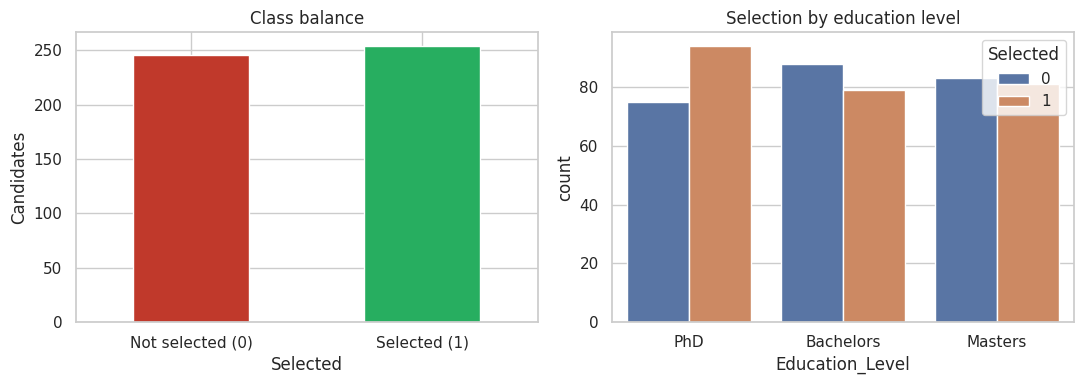

Selected
1    0.508
0    0.492
Name: proportion, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y.value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#c0392b", "#27ae60"])
axes[0].set_xticklabels(["Not selected (0)", "Selected (1)"], rotation=0)
axes[0].set_title("Class balance")
axes[0].set_ylabel("Candidates")

sns.countplot(data=df, x="Education_Level", hue=TARGET, ax=axes[1])
axes[1].set_title("Selection by education level")
plt.tight_layout(); plt.show()

print(y.value_counts(normalize=True).round(3))

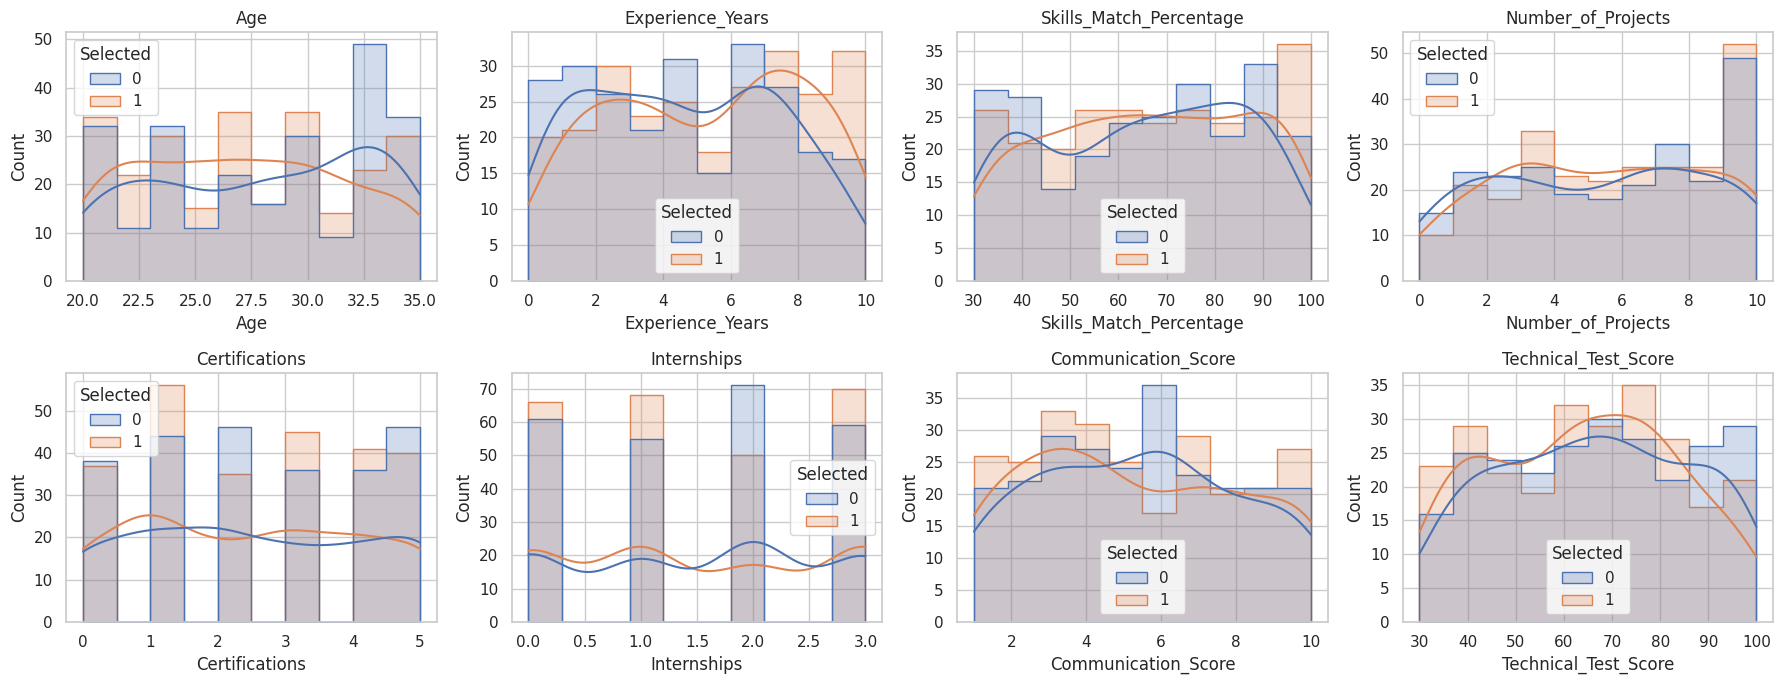

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, ax=ax, element="step")
    ax.set_title(col)
plt.tight_layout(); plt.show()

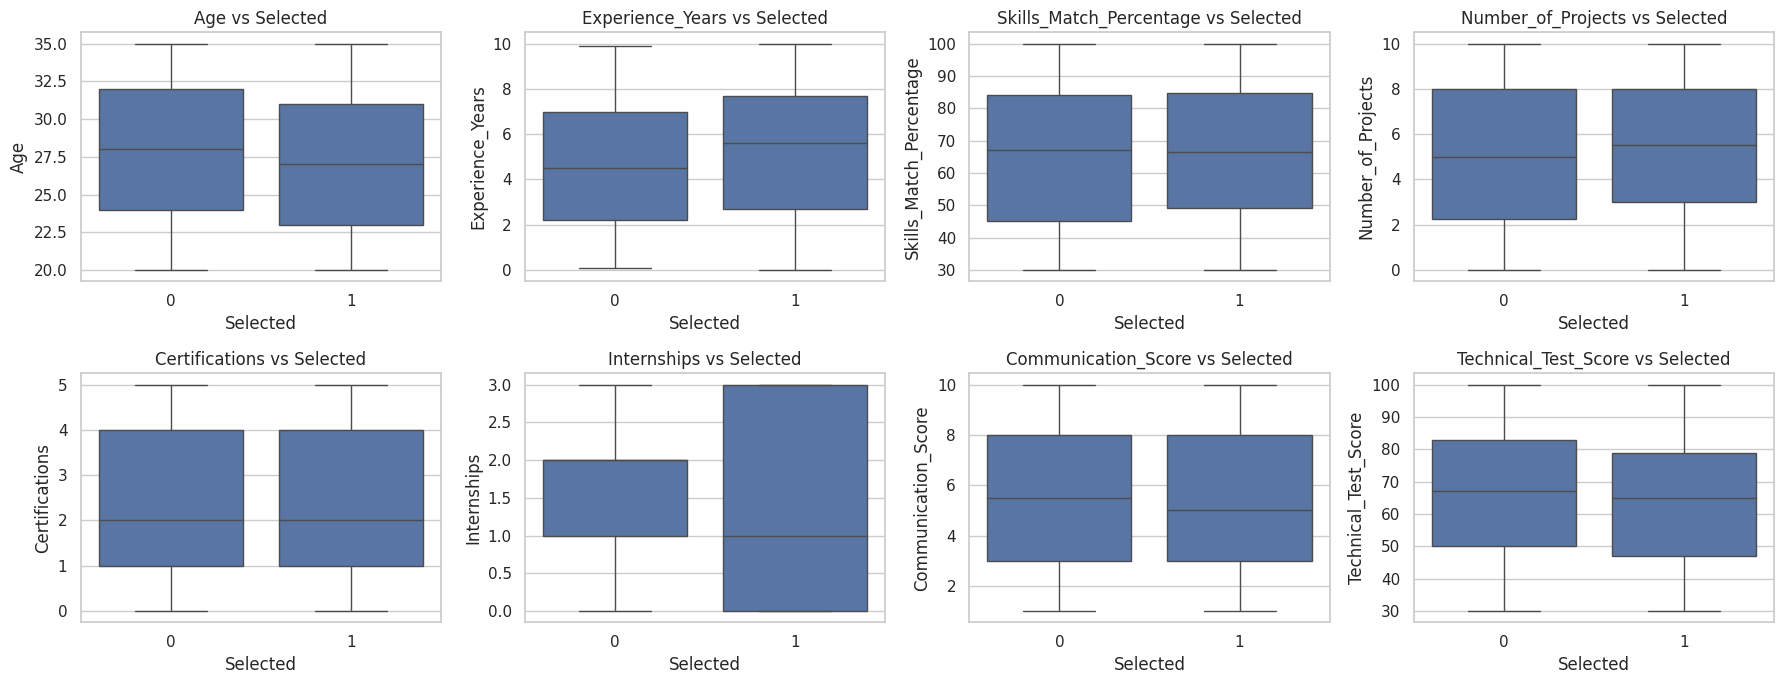

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(f"{col} vs {TARGET}")
plt.tight_layout(); plt.show()

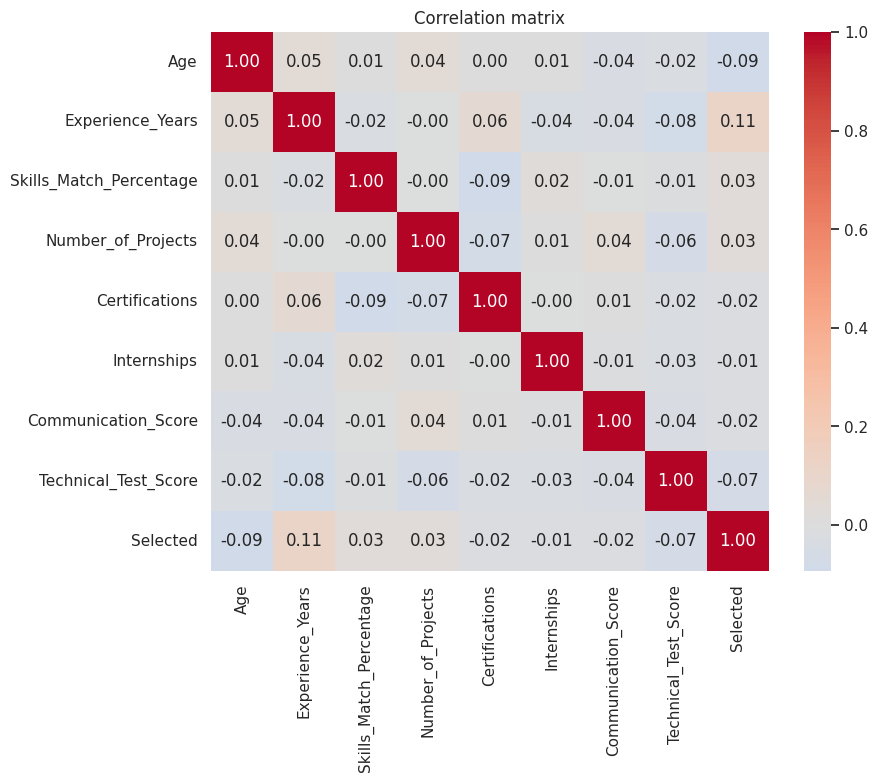

Correlation with target:
Experience_Years           0.114
Age                       -0.091
Technical_Test_Score      -0.066
Number_of_Projects         0.031
Skills_Match_Percentage    0.031
Communication_Score       -0.018
Certifications            -0.015
Internships               -0.014
Name: Selected, dtype: float64


In [9]:
plt.figure(figsize=(9, 7))
corr = df[num_cols + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print("Correlation with target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

## 4. Train / test split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (400, 9)  Test: (100, 9)


## 5. Baseline models
Each model sits in a pipeline with the preprocessor, so scaling is fitted on training folds only (no data leakage).

In [11]:
def make_pipe(model):
    return Pipeline([("prep", preprocessor), ("model", model)])

baselines = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Random Forest":       make_pipe(RandomForestClassifier(random_state=RANDOM_STATE)),
    "SVM":                 make_pipe(SVC(probability=True, random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in baselines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    rows.append({"Model": name, "CV ROC-AUC (mean)": scores.mean(), "CV ROC-AUC (std)": scores.std()})
pd.DataFrame(rows).round(4)

,Model,CV ROC-AUC (mean),CV ROC-AUC (std)
0,Logistic Regression,0.5198,0.0466
1,Random Forest,0.5339,0.0585
2,SVM,0.5019,0.0410


## 6. Hyperparameter tuning (GridSearchCV)

In [12]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__penalty": ["l2"],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [100, 300],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"],
    },
}

tuned = {}
for name, pipe in baselines.items():
    gs = GridSearchCV(pipe, param_grids[name], cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    print(f"{name:20s} best CV ROC-AUC = {gs.best_score_:.4f}")
    print("   best params:", gs.best_params_)

Logistic Regression  best CV ROC-AUC = 0.5208
   best params: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__penalty': 'l2'}


Random Forest        best CV ROC-AUC = 0.5492
   best params: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 100}


SVM                  best CV ROC-AUC = 0.5260
   best params: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}


## 7. Evaluation on the held-out test set

In [13]:
results, probas = [], {}
for name, model in tuned.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    probas[name] = proba
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "ROC-AUC":   roc_auc_score(y_test, proba),
    })
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.55,0.5652,0.5098,0.5361,0.5978
Random Forest,0.50,0.5085,0.5882,0.5455,0.5250
SVM,0.60,0.6038,0.6275,0.6154,0.3850


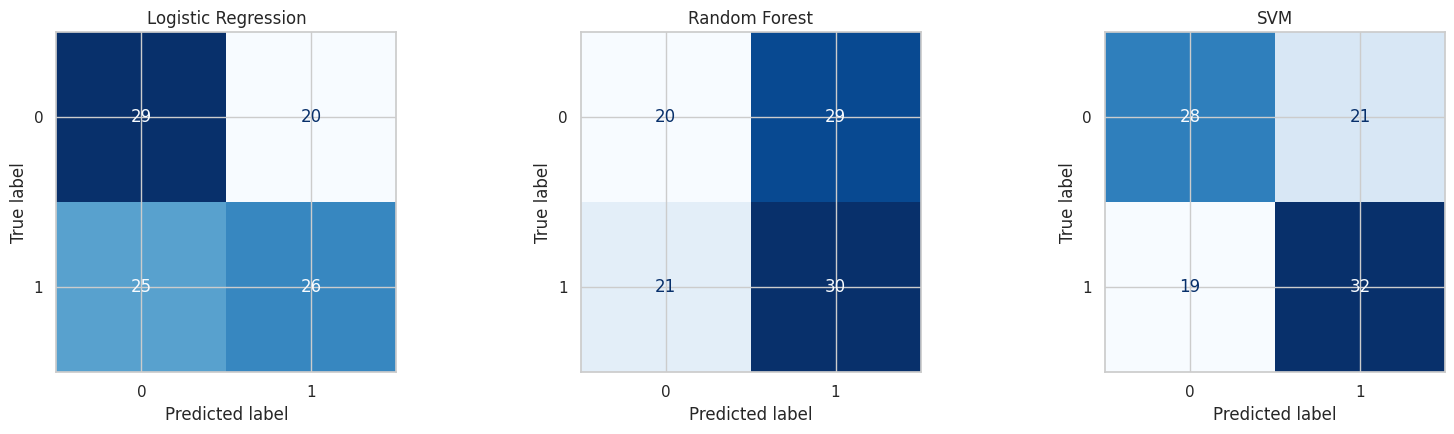

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, model) in zip(axes, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

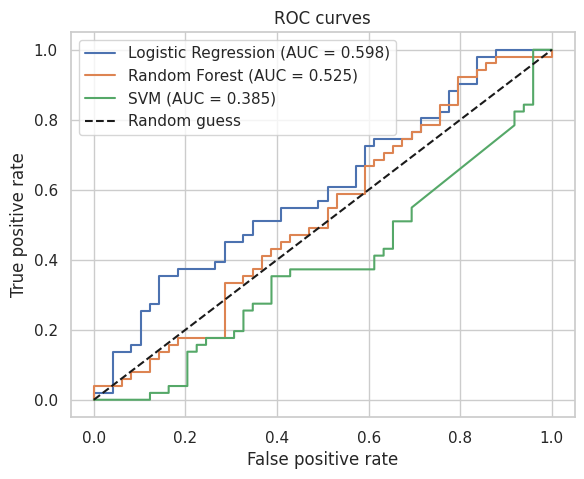

In [15]:
plt.figure(figsize=(6.5, 5))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend(); plt.show()

In [16]:
best_name = results_df["ROC-AUC"].idxmax()
print("Best model by test ROC-AUC:", best_name, "\n")
print(classification_report(y_test, tuned[best_name].predict(X_test),
                            target_names=["Not selected", "Selected"]))

Best model by test ROC-AUC: Logistic Regression 

              precision    recall  f1-score   support

Not selected       0.54      0.59      0.56        49
    Selected       0.57      0.51      0.54        51

    accuracy                           0.55       100
   macro avg       0.55      0.55      0.55       100
weighted avg       0.55      0.55      0.55       100



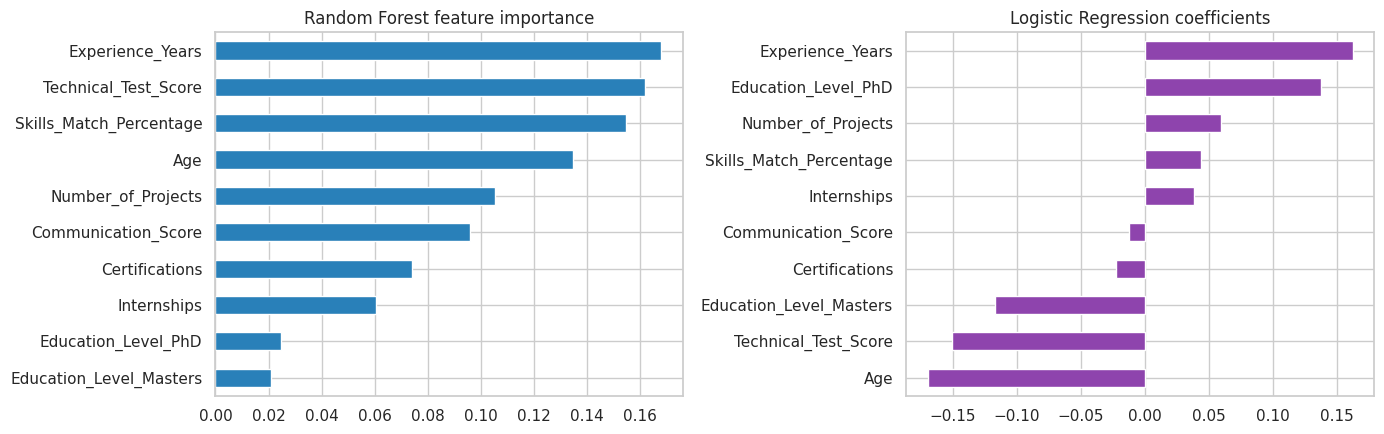

In [17]:
# Feature importance (Random Forest) and coefficients (Logistic Regression)
feat_names = tuned["Random Forest"].named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__")[-1] for f in feat_names]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rf_imp = pd.Series(tuned["Random Forest"].named_steps["model"].feature_importances_, index=feat_names).sort_values()
rf_imp.plot(kind="barh", ax=axes[0], color="#2980b9"); axes[0].set_title("Random Forest feature importance")

lr_coef = pd.Series(tuned["Logistic Regression"].named_steps["model"].coef_[0], index=feat_names).sort_values()
lr_coef.plot(kind="barh", ax=axes[1], color="#8e44ad"); axes[1].set_title("Logistic Regression coefficients")
plt.tight_layout(); plt.show()

## 8. Candidate scoring system
Raw data becomes a **0–100 Hiring Score** for every candidate:

1. Use the best model's predicted probability of selection, multiplied by 100.
2. Scores come from **out-of-fold predictions** (5-fold cross-validation), so each candidate is scored by a model that never saw them during training.
3. Candidates are ranked and grouped into recommendation tiers.

In [18]:
best_model = tuned[best_name]
oof_proba = cross_val_predict(best_model, X, y, cv=cv, method="predict_proba")[:, 1]

scored = df.copy()
scored["Hiring_Score"] = (oof_proba * 100).round(2)
scored["Rank"] = scored["Hiring_Score"].rank(ascending=False, method="min").astype(int)

# Tiers by score quartile
scored["Recommendation"] = pd.qcut(
    scored["Hiring_Score"], q=4,
    labels=["Low priority", "Consider", "Strong", "Top candidate"])

ranked = scored.sort_values("Rank").reset_index(drop=True)
cols = ["Rank", "Candidate_ID", "Hiring_Score", "Recommendation", "Selected",
        "Skills_Match_Percentage", "Technical_Test_Score", "Experience_Years"]
ranked[cols].head(15)

,Rank,Candidate_ID,Hiring_Score,Recommendation,Selected,Skills_Match_Percentage,Technical_Test_Score,Experience_Years
0,1,CAND1256,73.52,Top candidate,0,63,55,9.4
1,2,CAND1410,73.51,Top candidate,0,75,36,6.8
2,3,CAND1054,72.70,Top candidate,0,70,71,9.6
3,4,CAND1291,70.14,Top candidate,0,30,34,9.5
4,5,CAND1491,69.48,Top candidate,1,87,31,9.1
5,6,CAND1245,69.20,Top candidate,1,48,35,8.4
6,7,CAND1084,68.95,Top candidate,1,96,47,9.3
7,8,CAND1404,67.44,Top candidate,0,92,49,7.9
8,9,CAND1007,67.10,Top candidate,0,64,38,4.2
9,10,CAND1446,66.83,Top candidate,1,64,51,9.0


In [19]:
# Does a higher score actually mean a higher selection rate?
tier_check = scored.groupby("Recommendation", observed=True).agg(
    Candidates=("Candidate_ID", "count"),
    Avg_Score=("Hiring_Score", "mean"),
    Actual_Selection_Rate=("Selected", "mean")).round(3)
tier_check

,Candidates,Avg_Score,Actual_Selection_Rate
Recommendation,,,
Low priority,125,39.139,0.440
Consider,125,47.359,0.512
Strong,126,53.091,0.532
Top candidate,124,61.007,0.548


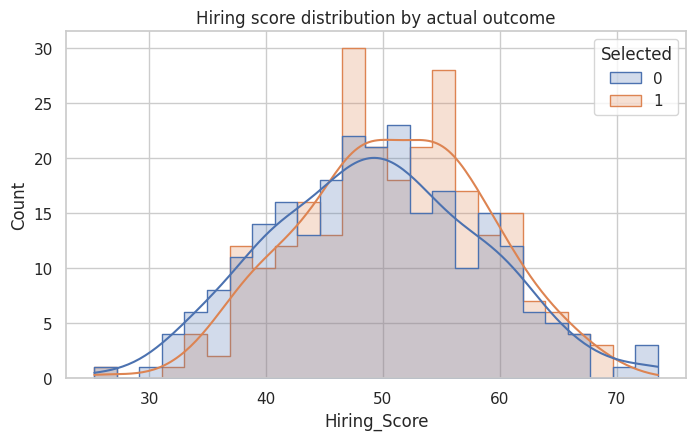

In [20]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=scored, x="Hiring_Score", hue="Selected", bins=25, element="step", kde=True)
plt.title("Hiring score distribution by actual outcome")
plt.show()

In [21]:
ranked[cols].to_csv("ranked_candidates.csv", index=False)
print("Saved ranked_candidates.csv with", len(ranked), "candidates")

Saved ranked_candidates.csv with 500 candidates


## 9. Reading the results honestly
On this dataset every model performs close to chance: cross-validated ROC-AUC is roughly 0.50-0.55, and no feature has more than about 0.11 correlation with `Selected`. Test-set differences between models (for example SVM accuracy vs. its ROC-AUC) are noise from a small 100-row test set, so no model is meaningfully better than the others here. This is typical of synthetic or randomly generated screening data. The pipeline, tuning and scoring framework are what matter, and they will produce real signal on a dataset where hiring outcomes depend on the features.

Higher-score tiers do show a slightly higher actual selection rate (see the tier table above), but the effect is small.

## 10. Summary
- Three classifiers (Logistic Regression, Random Forest, SVM) were built in leakage-safe pipelines and tuned with 5-fold GridSearchCV on ROC-AUC.
- Models were compared on a held-out test set using accuracy, precision, recall, F1 and ROC-AUC.
- The best model's probabilities were converted into a 0–100 hiring score, ranking all candidates into tiers.
- Gender and Candidate_ID were excluded from the features to avoid biased or meaningless predictors.